In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def read_frame_with_stride(raw_file, frame_idx=0, width=4056, height=3040, stride=8128, dtype=np.uint16):
    """
    Reads a single frame from a multi-frame raw file with stride-aware unpacking.
    Assumes 16-bit unpacked SBGGR16 format.
    
    Parameters:
        raw_file (str): Path to the .raw file.
        frame_idx (int): Index of the frame to read (0-based).
        width (int): Width of the image in pixels.
        height (int): Height of the image in pixels.
        stride (int): Bytes per row (may be more than width * 2).
        dtype: Data type of the pixel values (np.uint16 for SBGGR16).
    Returns:
        np.ndarray: Image array of shape (height, width).
    """
    row_bytes = stride
    frame_bytes = row_bytes * height

    with open(raw_file, 'rb') as f:
        f.seek(frame_idx * frame_bytes)
        raw_frame = f.read(frame_bytes)

    # Convert to 1D array of 16-bit unsigned ints
    raw_data = np.frombuffer(raw_frame, dtype=dtype)

    # Reshape to (height, stride//2) and crop to (height, width)
    full_width = stride // 2  # since each pixel is 2 bytes
    raw_2d = raw_data.reshape((height, full_width))
    image = raw_2d[:, :width]  # Crop to actual width

    return image

def visualize_bayer_pattern(image, x_start=0, y_start=0, size=40):
    """
    Visualize a cropped region of the Bayer raw image.
    """
    region = image[y_start:y_start+size, x_start:x_start+size]
    plt.figure(figsize=(6, 6))
    plt.imshow(region, cmap='gray', interpolation='nearest')
    plt.title(f"Cropped Bayer Pattern Region ({x_start},{y_start})")
    plt.colorbar()
    plt.show()

In [3]:
ms = 1

In [7]:
import os

In [8]:
os.chdir('/gpfs01/euler/User/ydeng/Github/SCAM/pics/g_raw/')

In [9]:
clean_shutter_toPlot =[]
for ms in [1,10,20,30,50,100]:
    raw_path = f"g_{str(ms)}ms.raw"
    frame = read_frame_with_stride(raw_path, frame_idx=0)
    #im = plt.imshow(frame,cmap='gray')
    #plt.colorbar(im)
    #plt.title('raw',fontsize=16)
    #figname = raw_path.replace('.raw','.png')
    #plt.savefig(figname)
    print(f'min: {np.min(frame)}, max: {np.max(frame)}, max_wo_darkNoise: {np.max(frame)-np.min(frame)}, shutter: {ms}ms')
    
    clean_shutter_toPlot.append(np.max(frame)-np.min(frame))
    del frame
    #plt.close()

FileNotFoundError: [Errno 2] No such file or directory: 'g_1ms.raw'

Text(0, 0.5, '16bit raw readout')

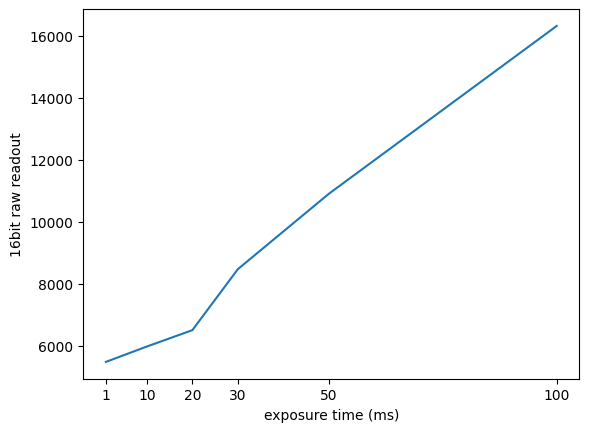

In [241]:
shutters= [1,10,20,30,50,100]
plt.plot(shutters,clean_gain_toPlot)
plt.xticks(shutters,shutters)
plt.xlabel('exposure time (ms)')
plt.ylabel('16bit raw readout')

In [4]:
ags=[1,1.1,2,3,4,5,6,7,8]

In [ ]:
data = frame.flatten()

# Define bin edges
#bin_edges = np.linspace(data.min(), data.max(), 20)
bin_edges = np.linspace(0, 65520, 20)

# Get counts per bin
counts, edges = np.histogram(data, bins=bin_edges)

# Plot
plt.hist(data, bins=edges, edgecolor='black')
plt.xlim([0,65520])
plt.show()

In [73]:
clean_gain_toPlot = []
for ms in [ms]:
    for ag in ags:
        raw_path = f"g_{str(ms)}ms_gain{str(ag)}.raw"
        frame = read_frame_with_stride(raw_path, frame_idx=0)
        deNoise_frame = np.where(frame<4096,0,frame-4096)
        
        plt.figure(figsize=(10, 4)) 
        plt.subplot(121)
        #im = plt.imshow(frame,cmap='gray')
        im=plt.imshow(deNoise_frame,cmap='gray')
        plt.colorbar(im)
        plt.title('raw',fontsize=16)
        figname = raw_path.replace('.raw','.png')

        plt.subplot(122)
        #data = frame.flatten()
        data = deNoise_frame.flatten()
        bin_edges = np.linspace(0, 65520, 25)
        counts, edges = np.histogram(data, bins=bin_edges)
        plt.hist(data, bins=edges, edgecolor='black')
        plt.xlim([0,65520])
        
        plt.savefig(figname)
        # print(f'min: {np.min(frame)}, max: {np.max(frame)}, max_wo_darkNoise: {np.max(frame)-np.min(frame)}, gain: {ag}, shutter: {ms}ms')
        # clean_gain_toPlot.append(np.max(frame)-np.min(frame))
        print(f'min: {np.min(deNoise_frame)}, max: {np.max(deNoise_frame)}, mean_pxlValue: {np.sum(deNoise_frame)/3040/4056}, gain: {ag}, shutter: {ms}ms')
        clean_gain_toPlot.append(np.sum(deNoise_frame/3040/4056))

        del frame
        plt.close()
        

min: 0, max: 1312, mean_pxlValue: 494.95096672895255, gain: 1, shutter: 1ms
min: 0, max: 1536, mean_pxlValue: 542.2086058341118, gain: 1.1, shutter: 1ms
min: 0, max: 2624, mean_pxlValue: 981.4117603550296, gain: 2, shutter: 1ms
min: 0, max: 3824, mean_pxlValue: 1478.612945084605, gain: 3, shutter: 1ms
min: 0, max: 5296, mean_pxlValue: 1964.6685547077755, gain: 4, shutter: 1ms
min: 0, max: 6448, mean_pxlValue: 2449.958664227136, gain: 5, shutter: 1ms
min: 0, max: 7904, mean_pxlValue: 2953.014842209073, gain: 6, shutter: 1ms
min: 0, max: 8976, mean_pxlValue: 3425.3966287760823, gain: 7, shutter: 1ms
min: 0, max: 10304, mean_pxlValue: 3919.445628308938, gain: 8, shutter: 1ms


Text(0.5, 0, 'analoggain')

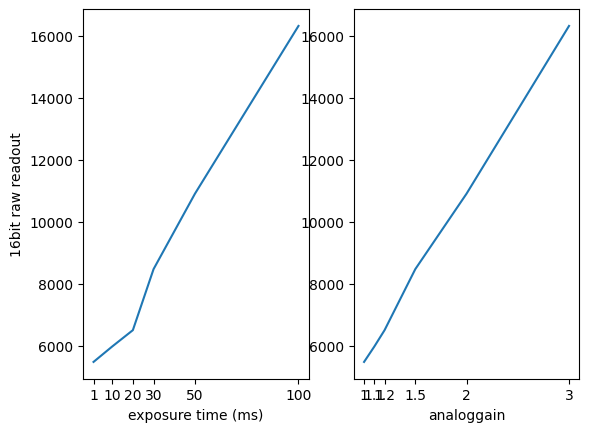

In [243]:
plt.subplot(121)
shutters= [1,10,20,30,50,100]
plt.plot(shutters,clean_gain_toPlot)
plt.xticks(shutters,shutters)
plt.xlabel('exposure time (ms)')
plt.ylabel('16bit raw readout')
plt.subplot(122)
plt.plot(ags,clean_gain_toPlot)
plt.xticks(ags,ags)
plt.xlabel('analoggain')
#plt.ylabel('16bit raw readout')

In [15]:
np.min(frame-np.min(frame)),np.max(frame-np.min(frame))

(0, 3120)

In [16]:
np.min(frame)

3600

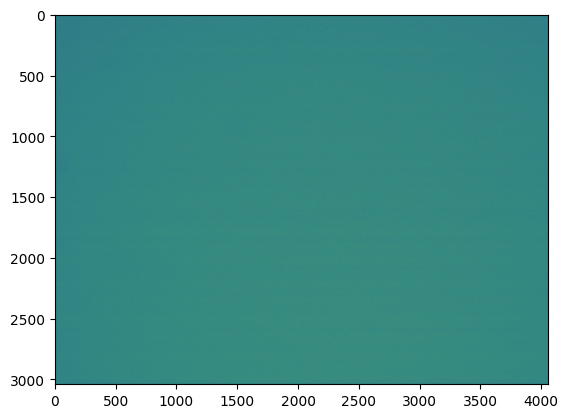

In [17]:
plt.imshow(frame)

In [13]:
im = plt.imshow(frame-np.min(frame),cmap='gray')
plt.colorbar(im)
plt.title('raw',fontsize=16)

NameError: name 'frame' is not defined

Text(0.5, 1.0, 'raw')

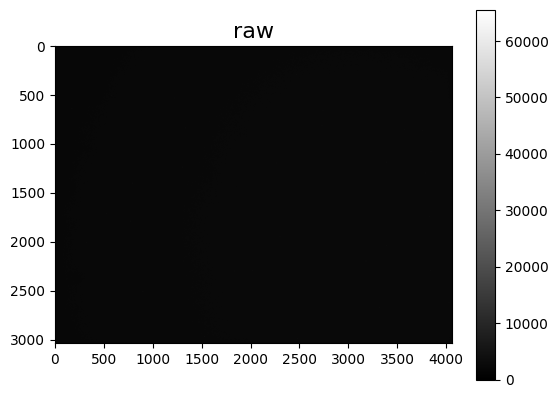

In [187]:
im = plt.imshow(frame-4096,cmap='gray')
plt.colorbar(im)
plt.title('raw',fontsize=16)

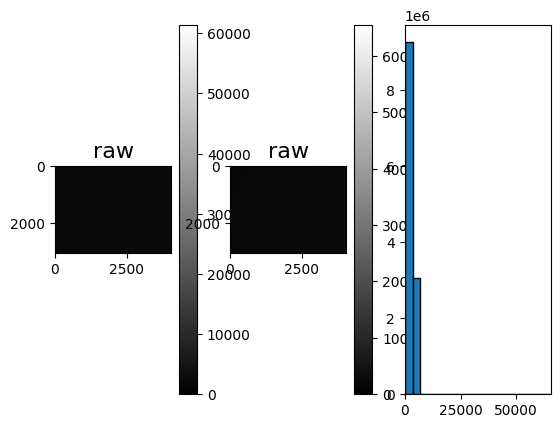

In [198]:
plt.subplot(131)
im = plt.imshow(frame,cmap='gray',vmin=0, vmax=65520-4096)
plt.colorbar(im)
plt.title('raw',fontsize=16)
plt.subplot(132)
im = plt.imshow(frame,cmap='gray')
plt.colorbar(im)
plt.title('raw',fontsize=16)
plt.subplot(133)
data = frame.flatten()

# Define bin edges
#bin_edges = np.linspace(data.min(), data.max(), 20)
bin_edges = np.linspace(0, 65520, 20)

# Get counts per bin
counts, edges = np.histogram(data, bins=bin_edges)

# Plot
plt.hist(data, bins=edges, edgecolor='black')
plt.xlim([0,65520])
plt.show()

In [190]:
np.max(frame.flatten())

9392

In [191]:
np.log2(np.max(frame.flatten()))

13.197217

In [192]:
np.power(2,16)

65536

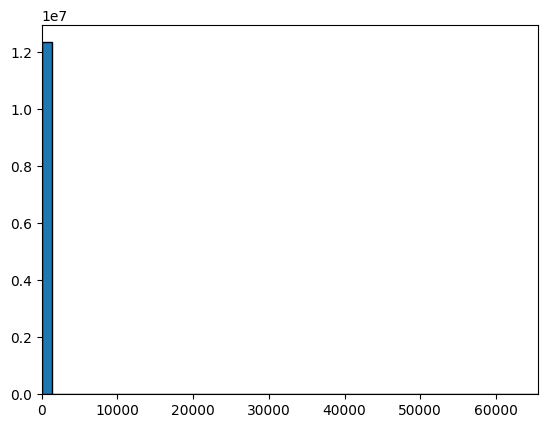

[0.000, 1337.143): 12330197
[1337.143, 2674.286): 43
[2674.286, 4011.429): 0
[4011.429, 5348.571): 0
[5348.571, 6685.714): 0
[6685.714, 8022.857): 0
[8022.857, 9360.000): 0
[9360.000, 10697.143): 0
[10697.143, 12034.286): 0
[12034.286, 13371.429): 0
[13371.429, 14708.571): 0
[14708.571, 16045.714): 0
[16045.714, 17382.857): 0
[17382.857, 18720.000): 0
[18720.000, 20057.143): 0
[20057.143, 21394.286): 0
[21394.286, 22731.429): 0
[22731.429, 24068.571): 0
[24068.571, 25405.714): 0
[25405.714, 26742.857): 0
[26742.857, 28080.000): 0
[28080.000, 29417.143): 0
[29417.143, 30754.286): 0
[30754.286, 32091.429): 0
[32091.429, 33428.571): 0
[33428.571, 34765.714): 0
[34765.714, 36102.857): 0
[36102.857, 37440.000): 0
[37440.000, 38777.143): 0
[38777.143, 40114.286): 0
[40114.286, 41451.429): 0
[41451.429, 42788.571): 0
[42788.571, 44125.714): 0
[44125.714, 45462.857): 0
[45462.857, 46800.000): 0
[46800.000, 48137.143): 0
[48137.143, 49474.286): 0
[49474.286, 50811.429): 0
[50811.429, 52148.571)

In [66]:
import numpy as np
import matplotlib.pyplot as plt

data = deNoise_frame.flatten()

# Define bin edges
#bin_edges = np.linspace(data.min(), data.max(), 20)
bin_edges = np.linspace(0, 65520, 50)

# Get counts per bin
counts, edges = np.histogram(data, bins=bin_edges)

# Plot
plt.hist(data, bins=edges, edgecolor='black')
plt.xlim([0,65520])
plt.show()

# Inspect counts per range
for i in range(len(counts)):
    print(f"[{edges[i]:.3f}, {edges[i+1]:.3f}): {counts[i]}")


In [67]:
np.sum(deNoise_frame)/3040/4056

542.2086058341118

In [57]:
# top49 = np.sort(data)[3:30]
# top49

In [59]:
deNoise_frame= np.where(frame<4096,0,frame-4096)

In [62]:
np.min(frame),np.max(frame)

(3872, 5632)

In [63]:
np.min(deNoise_frame),np.max(deNoise_frame)

(0, 1536)

In [15]:
# Example usage:
raw_path = "./cam0_raw_zz.raw"
frame = read_frame_with_stride(raw_path, frame_idx=0)
#visualize_bayer_pattern(frame)# x_start=100, y_start=100, size=40)

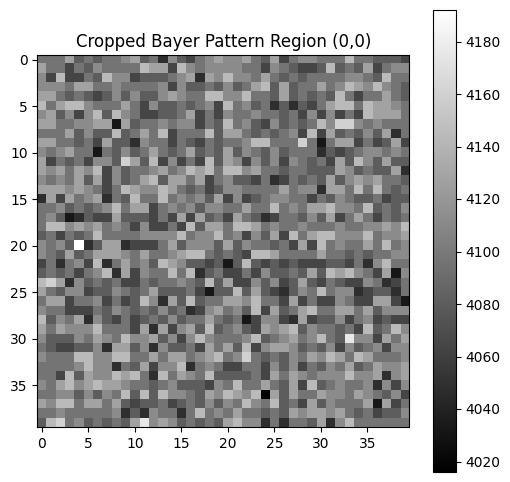

In [10]:
visualize_bayer_pattern(frame)# x_start=100, y_start=100, size=40)